<a href="https://colab.research.google.com/github/jmora420-hue/bigData/blob/main/Spark_MLlib_0A_documentado_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
# =============================================================================
# 1. CARGA DE LIBRERÍAS E INICIALIZACIÓN DE SPARK
# =============================================================================

import re
import unicodedata
import json
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import DoubleType

SEED = 42
N_PARTICIONES = 4

spark = (SparkSession.builder
         .appName("Predicción Estudiantes")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", str(N_PARTICIONES))
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

np.random.seed(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

print("Versión de Spark:", spark.version)

Versión de Spark: 4.0.5


In [38]:
# =============================================================================
# 1.2 MONTAJE DE GOOGLE DRIVE Y LECTURA DEL DATASET
# =============================================================================

from google.colab import drive
drive.mount('/content/drive')

url = "/content/drive/MyDrive/Colab Notebooks/dataset.csv"
df_pd = pd.read_csv(url)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [39]:
# =============================================================================
# 1.3 INSPECCIÓN Y DIAGNÓSTICO DEL DATAFRAME ORIGINAL
# =============================================================================

display(df_pd.head())
print("\nInformación del DataFrame:")
df_pd.info()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000,0,10.800,1.400,1.740,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.667,0,13.900,-0.300,0.790,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000,0,10.800,1.400,1.740,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400,0,9.400,-0.800,-3.120,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000,0,13.900,-0.300,0.790,Graduate



Información del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occu

In [40]:
# =============================================================================
# 2. LIMPIEZA Y NORMALIZACIÓN DE COLUMNAS
# =============================================================================

def normalizar(nombre):
    n = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode()
    n = re.sub(r"[^0-9a-z]+", "_", n.strip().lower())
    return n.strip("_")

df_pd.columns = [normalizar(c) for c in df_pd.columns]
assert len(set(df_pd.columns)) == len(df_pd.columns), "Nombres de columna repetidos tras normalizar"
print("Columnas normalizadas:", list(df_pd.columns))

Columnas normalizadas: ['marital_status', 'application_mode', 'application_order', 'course', 'daytime_evening_attendance', 'previous_qualification', 'nacionality', 'mother_s_qualification', 'father_s_qualification', 'mother_s_occupation', 'father_s_occupation', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'age_at_enrollment', 'international', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'curricular_units_1st_sem_without_evaluations', 'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations', 'unemployment_rate', 'inflation_rate', 'gdp', 'target']


In [41]:
# =============================================================================
# 2.2 ELIMINACIÓN DE DUPLICADOS Y PASO A PYSPARK
# =============================================================================

# Convertir pandas DataFrame a Spark DataFrame
sdf = spark.createDataFrame(df_pd)

n_total = sdf.count()
n_dup = n_total - sdf.dropDuplicates().count()
print(f"Filas totales: {n_total} | Filas duplicadas detectadas: {n_dup}")

if n_dup > 0:
    sdf = sdf.dropDuplicates()
    print("Duplicados eliminados de forma exitosa. Filas restantes en Spark:", sdf.count())
else:
    print("No se encontraron duplicados en el set de datos.")

Filas totales: 4424 | Filas duplicadas detectadas: 0
No se encontraron duplicados en el set de datos.


In [42]:
# =============================================================================
# 3.1 SELECCIÓN DE VARIABLES Y PREPARACIÓN DEL ESQUEMA
# =============================================================================

TARGET = "target"
LABEL = "label"

FEATURES = [
    "curricular_units_1st_sem_approved",
    "curricular_units_2nd_sem_approved",
    "tuition_fees_up_to_date",
]

faltantes = [c for c in FEATURES + [TARGET] if c not in sdf.columns]
assert not faltantes, f"Columnas no encontradas: {faltantes}"

# Filtrar y castear las columnas a DoubleType para Spark MLlib
sdf = sdf.select(*[F.col(c).cast(DoubleType()).alias(c) for c in FEATURES],
                 F.col(TARGET))

sdf.printSchema()
sdf.show(5)

root
 |-- curricular_units_1st_sem_approved: double (nullable = true)
 |-- curricular_units_2nd_sem_approved: double (nullable = true)
 |-- tuition_fees_up_to_date: double (nullable = true)
 |-- target: string (nullable = true)

+---------------------------------+---------------------------------+-----------------------+--------+
|curricular_units_1st_sem_approved|curricular_units_2nd_sem_approved|tuition_fees_up_to_date|  target|
+---------------------------------+---------------------------------+-----------------------+--------+
|                              0.0|                              0.0|                    1.0| Dropout|
|                              6.0|                              6.0|                    0.0|Graduate|
|                              0.0|                              0.0|                    0.0| Dropout|
|                              6.0|                              5.0|                    1.0|Graduate|
|                              5.0|               

In [43]:
# =============================================================================
# 3.2 INDEXACIÓN DE LA VARIABLE OBJETIVO (LABEL INDEXING)
# =============================================================================

from pyspark.ml.feature import StringIndexer

# Crear el indexador para convertir la variable de texto objetivo en un índice numérico
indexer = StringIndexer(inputCol=TARGET, outputCol=LABEL)
sdf_indexed = indexer.fit(sdf).transform(sdf)

# Mostrar la correspondencia entre los strings originales y los índices asignados
sdf_indexed.select(TARGET, LABEL).distinct().show()

# Actualizar nuestra referencia principal para los siguientes pasos
sdf = sdf_indexed


+--------+-----+
|  target|label|
+--------+-----+
|Graduate|  0.0|
|Enrolled|  2.0|
| Dropout|  1.0|
+--------+-----+



In [44]:
# =============================================================================
# 3.3 ENSAMBLADO DE CARACTERÍSTICAS (VECTOR ASSEMBLER)
# =============================================================================

from pyspark.ml.feature import VectorAssembler

# Agrupar las columnas predictoras especificadas en un único vector de características
assembler = VectorAssembler(inputCols=FEATURES, outputCol="features")
sdf_assembled = assembler.transform(sdf)

sdf_assembled.select("features", LABEL, TARGET).show(5, truncate=False)

# Actualizar nuestro Spark DataFrame principal para los pasos de modelado
sdf = sdf_assembled


+-------------+-----+--------+
|features     |label|target  |
+-------------+-----+--------+
|[0.0,0.0,1.0]|1.0  |Dropout |
|[6.0,6.0,0.0]|0.0  |Graduate|
|(3,[],[])    |1.0  |Dropout |
|[6.0,5.0,1.0]|0.0  |Graduate|
|[5.0,6.0,1.0]|0.0  |Graduate|
+-------------+-----+--------+
only showing top 5 rows


In [45]:
# =============================================================================
# 3.4 PARTICIÓN EN CONJUNTOS DE ENTRENAMIENTO Y PRUEBA (80/20)
# =============================================================================

# Cachear el DataFrame principal optimiza las operaciones repetitivas sobre el particionado
sdf = sdf.repartition(N_PARTICIONES).cache()

# Dividir de forma reproducible usando la semilla definida en la Sección 1
train_raw, test = sdf.randomSplit([0.8, 0.2], seed=SEED)

# Extraer dinámicamente las etiquetas a partir de los metadatos de la columna 'label' ya existente
meta = sdf.schema[LABEL].metadata
clases_mapeadas = meta["ml_attr"]["vals"]

print("Orden de clases indexado (índice -> clase original):")
for idx, clase in enumerate(clases_mapeadas):
    print(f"  {idx} -> {clase}")

# Función auxiliar para evaluar la distribución de las clases
def obtener_distribucion_clases(df_spark):
    conteos = df_spark.groupBy(LABEL).count().collect()
    # Mapear los índices de vuelta a sus nombres de clase originales para fácil lectura
    dist = {clases_mapeadas[int(r[LABEL])]: r["count"] for r in conteos}
    return dict(sorted(dist.items()))

print("\nDistribución en Entrenamiento (Antes del remuestreo):", obtener_distribucion_clases(train_raw))
print("Distribución en Prueba (Conservando balance natural): ", obtener_distribucion_clases(test))

Orden de clases indexado (índice -> clase original):
  0 -> Graduate
  1 -> Dropout
  2 -> Enrolled

Distribución en Entrenamiento (Antes del remuestreo): {'Dropout': 1147, 'Enrolled': 636, 'Graduate': 1801}
Distribución en Prueba (Conservando balance natural):  {'Dropout': 274, 'Enrolled': 158, 'Graduate': 408}


In [46]:
# =============================================================================
# 3.5 REMUESTREO COMBINADO (SUBMUESTREO Y SOBREMUESTREO DE ENTRENAMIENTO)
# =============================================================================

# Determinar los conteos de filas reales de cada clase en el set de entrenamiento crudo
conteos = {r[LABEL]: r["count"] for r in train_raw.groupBy(LABEL).count().collect()}
n_obj = sorted(conteos.values())[len(conteos) // 2]   # Definir el tamaño de la clase mediana como objetivo
print("Tamaño objetivo por clase (mediana de entrenamiento):", n_obj)

partes = []
for clase, n in conteos.items():
    parte = train_raw.filter(F.col(LABEL) == clase)
    if n != n_obj:
        # Submuestreo si es mayoritaria (n > n_obj), sobremuestreo con reemplazo si es minoritaria
        parte = parte.sample(withReplacement=(n_obj > n), fraction=n_obj / n, seed=SEED)
    partes.append(parte)

# Unir las clases ya balanceadas
train = partes[0]
for p in partes[1:]:
    train = train.union(p)

# Reparticionar y cachear el set de entrenamiento balanceado resultante
train = train.repartition(N_PARTICIONES).cache()
test = test.repartition(N_PARTICIONES).cache()

print("Nueva distribución en Entrenamiento (Balanceado):", obtener_distribucion_clases(train))
print("Número de particiones finales -> Entrenamiento:", train.rdd.getNumPartitions(), "| Prueba:", test.rdd.getNumPartitions())


Tamaño objetivo por clase (mediana de entrenamiento): 1147
Nueva distribución en Entrenamiento (Balanceado): {'Dropout': 1147, 'Enrolled': 1149, 'Graduate': 1146}
Número de particiones finales -> Entrenamiento: 4 | Prueba: 4


In [47]:
# =============================================================================
# 3.6 PIPELINE DE PREPROCESAMIENTO Y CONFIGURACIÓN DEL EVALUADOR
# =============================================================================

from pyspark.ml.feature import StandardScaler, ChiSqSelector
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

def etapas_preprocesamiento(cols):
    """
    Genera las etapas secuenciales para el preprocesamiento de características:
    1. VectorAssembler: Agrupa las columnas en un vector crudo.
    2. ChiSqSelector: Filtra las características basándose en la prueba Chi-cuadrado.
    3. StandardScaler: Normaliza las características seleccionadas con media y desviación estándar.
    """
    return [
        VectorAssembler(inputCols=cols, outputCol="features_crudo"),
        ChiSqSelector(featuresCol="features_crudo", outputCol="features_sel",
                      labelCol=LABEL, selectorType="fpr", fpr=0.05),
        StandardScaler(inputCol="features_sel", outputCol="features",
                       withMean=True, withStd=True),
    ]

# Definir el evaluador usando el F1-score ponderado (métrica de optimización para clases multiclase)
evaluador_f1 = MulticlassClassificationEvaluator(labelCol=LABEL,
                                                 predictionCol="prediction",
                                                 metricName="f1")

print("Etapas de preprocesamiento y evaluador configurados exitosamente.")


Etapas de preprocesamiento y evaluador configurados exitosamente.


In [48]:
# =============================================================================
# 3.7 REGRESIÓN LOGÍSTICA MULTINOMIAL CON VALIDACIÓN CRUZADA
# =============================================================================

from pyspark.ml.classification import LogisticRegression
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml import Pipeline

# SOLUCIÓN: Eliminar la columna 'features' previa si ya existe para evitar colisiones con el Pipeline
if "features" in train.columns:
    train = train.drop("features")
if "features" in test.columns:
    test = test.drop("features")

# Definir el estimador base para regresión logística multinomial
lr = LogisticRegression(labelCol=LABEL, featuresCol="features",
                        family="multinomial", maxIter=100)

# Construir el Pipeline uniendo las etapas de preprocesamiento y el clasificador
pipe_lr = Pipeline(stages=etapas_preprocesamiento(FEATURES) + [lr])

# Definir la grilla de búsqueda de hiperparámetros
grid_lr = (ParamGridBuilder()
           .addGrid(lr.regParam, [0.0, 0.01, 0.1])
           .addGrid(lr.elasticNetParam, [0.0, 0.5])
           .build())

# Configurar la validación cruzada con 3 folds
cv_lr = CrossValidator(estimator=pipe_lr, estimatorParamMaps=grid_lr,
                       evaluator=evaluador_f1, numFolds=3, seed=SEED)

# Entrenar los modelos sobre el set balanceado
modelo_lr = cv_lr.fit(train)
mejor_lr = modelo_lr.bestModel.stages[-1]

print("Mejor Regresión Logística -> regParam:", mejor_lr.getRegParam(),
      "| elasticNetParam:", mejor_lr.getElasticNetParam())
print("Mejor F1 promedio obtenido en Validación Cruzada:", round(max(modelo_lr.avgMetrics), 4))

# Construir tabla comparativa en pandas para visualizar los resultados de la grilla
params_list_lr = []
for params, metric in zip(modelo_lr.getEstimatorParamMaps(), modelo_lr.avgMetrics):
    params_list_lr.append({
        "regParam": params[lr.regParam],
        "elasticNetParam": params[lr.elasticNetParam],
        "F1 promedio (CV)": round(metric, 4),
    })

df_comparativo_lr = pd.DataFrame(params_list_lr).sort_values(by="F1 promedio (CV)", ascending=False)
display(df_comparativo_lr)

Mejor Regresión Logística -> regParam: 0.1 | elasticNetParam: 0.0
Mejor F1 promedio obtenido en Validación Cruzada: 0.6515


,regParam,elasticNetParam,F1 promedio (CV)
4,0.100,0.000,0.651
2,0.010,0.000,0.650
1,0.000,0.500,0.649
0,0.000,0.000,0.649
5,0.100,0.500,0.647
3,0.010,0.500,0.647


In [49]:
# =============================================================================
# 3.8 RANDOM FOREST CON VALIDACIÓN CRUZADA
# =============================================================================

# Definir el clasificador Random Forest
rf = RandomForestClassifier(labelCol=LABEL, featuresCol="features", seed=SEED)

# Construir el Pipeline integrando preprocesamiento y el estimador Random Forest
pipe_rf = Pipeline(stages=etapas_preprocesamiento(FEATURES) + [rf])

# Definir la grilla de búsqueda de hiperparámetros
grid_rf = (ParamGridBuilder()
           .addGrid(rf.numTrees, [50, 100])
           .addGrid(rf.maxDepth, [5, 10])
           .build())

# Configurar la validación cruzada con 3 folds
cv_rf = CrossValidator(estimator=pipe_rf, estimatorParamMaps=grid_rf,
                       evaluator=evaluador_f1, numFolds=3, seed=SEED)

# Entrenar el modelo con el conjunto balanceado
modelo_rf = cv_rf.fit(train)
mejor_rf = modelo_rf.bestModel.stages[-1]

print("Mejor Random Forest -> numTrees:", mejor_rf.getNumTrees,
      "| maxDepth:", mejor_rf.getMaxDepth())
print("F1 promedio obtenido en Validación Cruzada:", round(max(modelo_rf.avgMetrics), 4))

# Generar tabla comparativa en pandas
params_list_rf = []
for params, metric in zip(modelo_rf.getEstimatorParamMaps(), modelo_rf.avgMetrics):
    params_list_rf.append({
        "numTrees": params[rf.numTrees],
        "maxDepth": params[rf.maxDepth],
        "F1 promedio (CV)": round(metric, 4),
    })

df_comparativo_rf = pd.DataFrame(params_list_rf).sort_values(by="F1 promedio (CV)", ascending=False)
display(df_comparativo_rf)

# Mostrar las variables que conservó ChiSqSelector (etapa 1 del mejor pipeline entrenado)
sel_idx = list(modelo_lr.bestModel.stages[1].selectedFeatures)
VARS_SEL = [FEATURES[i] for i in sel_idx]
print("\nVariables finales seleccionadas por ChiSqSelector:", VARS_SEL)


Mejor Random Forest -> numTrees: 100 | maxDepth: 10
F1 promedio obtenido en Validación Cruzada: 0.6878


,numTrees,maxDepth,F1 promedio (CV)
3,100,10,0.688
1,50,10,0.687
0,50,5,0.681
2,100,5,0.681



Variables finales seleccionadas por ChiSqSelector: ['curricular_units_1st_sem_approved', 'curricular_units_2nd_sem_approved', 'tuition_fees_up_to_date']


In [50]:
# =============================================================================
# 3.9 EVALUACIÓN GLOBAL Y DETALLADA EN EL CONJUNTO DE PRUEBA
# =============================================================================

from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import label_binarize
from pyspark.ml.functions import vector_to_array

# Recuperar el orden real de las clases del StringIndexer entrenado
CLASES = list(clases_mapeadas)

def evaluar_modelo_mllib(modelo, df_test):
    # Generar predicciones y aplicar caché para mejorar el rendimiento
    pred = modelo.transform(df_test).cache()

    def calcular_metrica(nombre_metrica, **kwargs):
        evaluador = MulticlassClassificationEvaluator(
            labelCol=LABEL, predictionCol="prediction", metricName=nombre_metrica, **kwargs
        )
        return evaluador.evaluate(pred)

    # Convertir predicciones a pandas para calcular métricas basadas en curvas (AUC-ROC y AUC-PR)
    pdf = pred.select(LABEL, vector_to_array("probability").alias("p")).toPandas()
    y_true = pdf[LABEL].astype(int).values
    y_prob = np.vstack(pdf["p"].values)
    y_true_binarized = label_binarize(y_true, classes=list(range(len(CLASES))))

    # Diccionario de métricas globales
    metricas_globales = {
        "accuracy": calcular_metrica("accuracy"),
        "precisión (pond.)": calcular_metrica("weightedPrecision"),
        "recall (pond.)": calcular_metrica("weightedRecall"),
        "F1 (pond.)": calcular_metrica("f1"),
        "AUC-ROC (OvR macro)": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro"),
        "AUC-PR (OvR macro)": average_precision_score(y_true_binarized, y_prob, average="macro"),
    }

    # Diccionario de métricas detalladas por clase individual
    metricas_por_clase = {
        clase: {
            "precisión": calcular_metrica("precisionByLabel", metricLabel=float(i)),
            "recall": calcular_metrica("recallByLabel", metricLabel=float(i)),
            "F1": calcular_metrica("fMeasureByLabel", metricLabel=float(i)),
        } for i, clase in enumerate(CLASES)
    }

    return pred, metricas_globales, metricas_por_clase, (y_true, y_prob)

# Ejecutar evaluación para ambos modelos
pred_lr, glob_lr, clase_lr, datos_lr = evaluar_modelo_mllib(modelo_lr.bestModel, test)
pred_rf, glob_rf, clase_rf, datos_rf = evaluar_modelo_mllib(modelo_rf.bestModel, test)

# Presentar tabla comparativa global
df_globales = pd.DataFrame({
    "Regresión Logística": glob_lr,
    "Random Forest": glob_rf
}).T

print("--- COMPARATIVA DE MÉTRICAS GLOBALES ---")
display(df_globales)

print("\n--- MÉTRICAS DETALLADAS POR CLASE: REGRESIÓN LOGÍSTICA ---")
display(pd.DataFrame(clase_lr).T)

print("\n--- MÉTRICAS DETALLADAS POR CLASE: RANDOM FOREST ---")
display(pd.DataFrame(clase_rf).T)


--- COMPARATIVA DE MÉTRICAS GLOBALES ---


,accuracy,precisión (pond.),recall (pond.),F1 (pond.),AUC-ROC (OvR macro),AUC-PR (OvR macro)
Regresión Logística,0.745,0.749,0.745,0.746,0.837,0.689
Random Forest,0.725,0.747,0.725,0.732,0.846,0.707



--- MÉTRICAS DETALLADAS POR CLASE: REGRESIÓN LOGÍSTICA ---


,precisión,recall,F1
Graduate,0.795,0.848,0.821
Dropout,0.829,0.726,0.774
Enrolled,0.491,0.513,0.502



--- MÉTRICAS DETALLADAS POR CLASE: RANDOM FOREST ---


,precisión,recall,F1
Graduate,0.805,0.809,0.807
Dropout,0.841,0.693,0.760
Enrolled,0.436,0.563,0.492


Matriz de Confusión - Regresión Logística:
               Predicho Graduate  Predicho Dropout  Predicho Enrolled
Real Graduate                346                17                 45
Real Dropout                  36               199                 39
Real Enrolled                 53                24                 81

Matriz de Confusión - Random Forest:
               Predicho Graduate  Predicho Dropout  Predicho Enrolled
Real Graduate                330                17                 61
Real Dropout                  30               190                 54
Real Enrolled                 50                19                 89


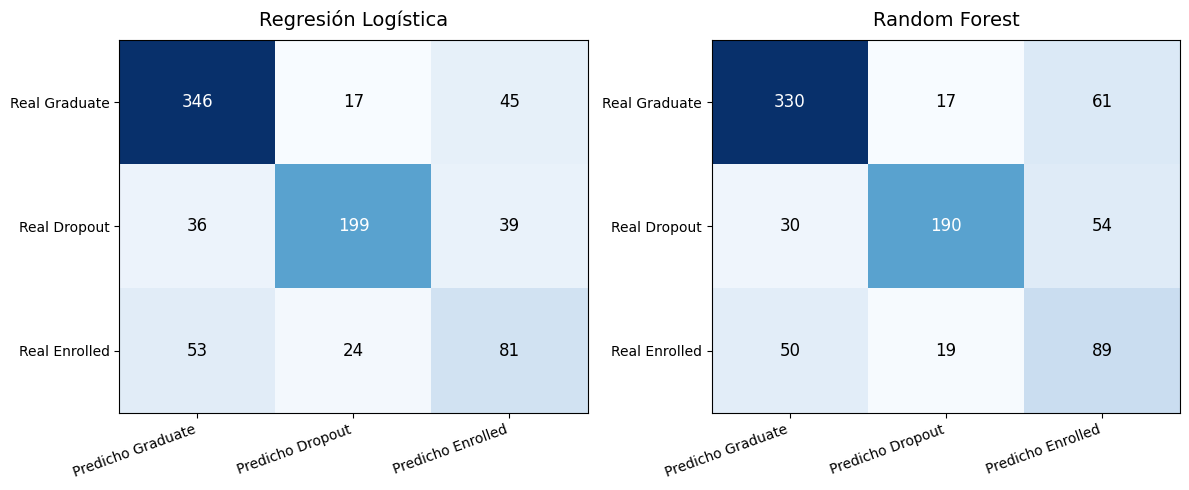

In [51]:
# =============================================================================
# 3.10 ANÁLISIS Y VISUALIZACIÓN DE MATRICES DE CONFUSIÓN
# =============================================================================

def generar_matriz_confusion(pred_df):
    # Construir la matriz agrupando las predicciones reales contra las predichas
    cm_pandas = (pred_df.groupBy(LABEL, "prediction").count().toPandas()
                 .pivot(index=LABEL, columns="prediction", values="count")
                 .reindex(index=range(len(CLASES)), columns=range(len(CLASES)))
                 .fillna(0).astype(int))
    cm_pandas.index = [f"Real {c}" for c in CLASES]
    cm_pandas.columns = [f"Predicho {c}" for c in CLASES]
    return cm_pandas

# Calcular las matrices para ambos modelos
cm_lr = generar_matriz_confusion(pred_lr)
cm_rf = generar_matriz_confusion(pred_rf)

print("Matriz de Confusión - Regresión Logística:")
print(cm_lr)
print("\nMatriz de Confusión - Random Forest:")
print(cm_rf)

# Generar mapas de calor visuales
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, cm, titulo in zip(ax, [cm_lr, cm_rf], ["Regresión Logística", "Random Forest"]):
    im = a.imshow(cm.values, cmap="Blues", aspect="auto")
    a.set_xticks(range(cm.shape[1]))
    a.set_xticklabels(cm.columns, rotation=20, ha="right")
    a.set_yticks(range(cm.shape[0]))
    a.set_yticklabels(cm.index)

    # Dibujar las anotaciones numéricas dentro de las celdas
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            a.text(j, i, format(cm.values[i, j], "d"),
                   ha="center", va="center",
                   color="white" if cm.values[i, j] > cm.values.max() / 2 else "black",
                   fontsize=12)
    a.set_title(titulo, fontsize=14, pad=10)

plt.tight_layout()
plt.show()


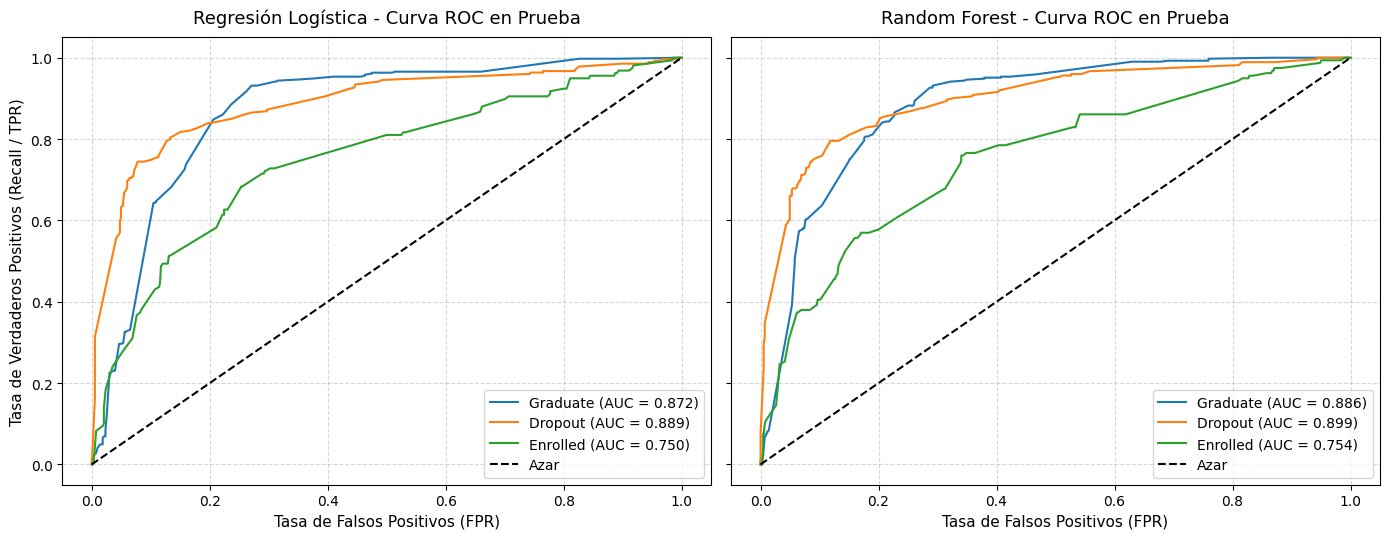

In [52]:
# =============================================================================
# 3.11 CURVAS ROC (UNO CONTRA EL RESTO)
# =============================================================================

from sklearn.metrics import roc_curve

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

# Iterar sobre los datos de predicciones y probabilidades guardados durante la evaluación
for a, (y_real, y_probabilidades), titulo in zip(ax, [datos_lr, datos_rf], ["Regresión Logística", "Random Forest"]):
    for k, clase in enumerate(CLASES):
        # Crear un objetivo binario para la clase actual (clase k vs el resto)
        y_binario = (y_real == k).astype(int)
        # Calcular la curva ROC
        fpr, tpr, _ = roc_curve(y_binario, y_probabilidades[:, k])
        auc_clase = roc_auc_score(y_binario, y_probabilidades[:, k])

        a.plot(fpr, tpr, label=f"{clase} (AUC = {auc_clase:.3f})")

    # Dibujar la línea de referencia diagonal (azar)
    a.plot([0, 1], [0, 1], "k--", label="Azar")
    a.set_xlabel("Tasa de Falsos Positivos (FPR)", fontsize=11)
    a.set_title(f"{titulo} - Curva ROC en Prueba", fontsize=13, pad=10)
    a.legend(loc="lower right")
    a.grid(True, linestyle="--", alpha=0.5)

ax[0].set_ylabel("Tasa de Verdaderos Positivos (Recall / TPR)", fontsize=11)
plt.tight_layout()
plt.show()


=== INTERPRETACIÓN DE LA REGRESIÓN LOGÍSTICA MULTINOMIAL ===

Coeficientes del Modelo (Log-Odds):


,curricular_units_1st_sem_approved,curricular_units_2nd_sem_approved,tuition_fees_up_to_date,Intercepto
Clase 0 (Graduate),0.298,0.482,0.267,-0.098
Clase 1 (Dropout),-0.236,-0.491,-0.363,-0.067
Clase 2 (Enrolled),-0.063,0.009,0.096,0.165



Razones de Momios (Odds Ratios):


,curricular_units_1st_sem_approved,curricular_units_2nd_sem_approved,tuition_fees_up_to_date
Clase 0 (Graduate),1.347,1.619,1.306
Clase 1 (Dropout),0.790,0.612,0.696
Clase 2 (Enrolled),0.939,1.009,1.101



=== IMPORTANCIA DE CARACTERÍSTICAS EN RANDOM FOREST ===



,Característica,Importancia Relativa
1,curricular_units_2nd_sem_approved,0.615
0,curricular_units_1st_sem_approved,0.266
2,tuition_fees_up_to_date,0.118


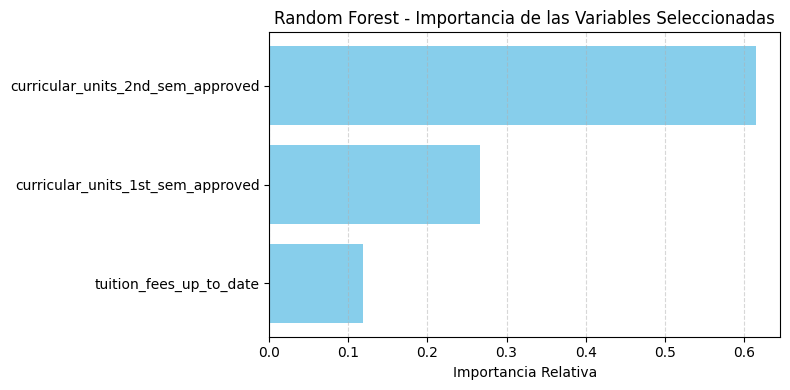

In [53]:
# =============================================================================
# 3.12 INTERPRETACIÓN DE MODELOS (COEFICIENTES E IMPORTANCIA)
# =============================================================================

# --- 1. Interpretación de la Regresión Logística Multinomial ---
print("=== INTERPRETACIÓN DE LA REGRESIÓN LOGÍSTICA MULTINOMIAL ===\n")

# Extraer los coeficientes estructurados en una matriz (filas: clases, columnas: variables)
coeficientes = mejor_lr.coefficientMatrix.toArray()
interceptos = mejor_lr.interceptVector.toArray()

# Generar un DataFrame explicativo para visualizar los coeficientes por clase
df_coefs = pd.DataFrame(
    coeficientes,
    index=[f"Clase {c} ({clase})" for i, (c, clase) in enumerate(zip(range(len(CLASES)), CLASES))],
    columns=VARS_SEL
)
df_coefs["Intercepto"] = interceptos

print("Coeficientes del Modelo (Log-Odds):")
display(df_coefs)

# Calcular y visualizar las razones de momios (Odds Ratios = exp(coefs)) para facilitar la interpretación directa
df_odds = np.exp(df_coefs.drop(columns=["Intercepto"]))
print("\nRazones de Momios (Odds Ratios):")
display(df_odds)

# --- 2. Interpretación de Random Forest ---
print("\n=== IMPORTANCIA DE CARACTERÍSTICAS EN RANDOM FOREST ===\n")

importancias = mejor_rf.featureImportances.toArray()

df_importancia = pd.DataFrame({
    "Característica": VARS_SEL,
    "Importancia Relativa": importancias
}).sort_values(by="Importancia Relativa", ascending=False)

display(df_importancia)

# Representar gráficamente las importancias
plt.figure(figsize=(8, 4))
plt.barh(df_importancia["Característica"], df_importancia["Importancia Relativa"], color="skyblue")
plt.xlabel("Importancia Relativa")
plt.title("Random Forest - Importancia de las Variables Seleccionadas")
plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [54]:
# =============================================================================
# 3.13 EXPORTACIÓN Y GUARDADO DE LOS MEJORES PIPELINES
# =============================================================================

import json
import shutil
from google.colab import files

# 1. Guardar la asignación de índices a clases originales en formato JSON
ruta_clases = "/content/orden_clases.json"
with open(ruta_clases, "w", encoding="utf-8") as f:
    json.dump(CLASES, f, ensure_ascii=False, indent=4)
print(f"Mapeo de clases exportado correctamente en: {ruta_clases}")

# Definir las rutas locales de guardado para los mejores modelos completos (Pipelines)
rutas_modelos = {
    "Regresión Logística": ("/content/mejor_modelo_regresion_logistica", modelo_lr.bestModel),
    "Random Forest": ("/content/mejor_modelo_random_forest", modelo_rf.bestModel)
}

# 2. Exportar los Pipelines y comprimirlos a archivos zip descargables
for nombre, (ruta, modelo_pipeline) in rutas_modelos.items():
    # Guardar el pipeline entrenado (incluye preprocesamiento y clasificador ajustado)
    modelo_pipeline.write().overwrite().save(ruta)
    print(f"Pipeline de {nombre} persistido localmente en: {ruta}")

    # Crear un archivo ZIP a partir del directorio del modelo exportado
    shutil.make_archive(ruta, 'zip', ruta)
    print(f"Archivo comprimido creado: {ruta}.zip\n")

# 3. Iniciar descargas automáticas en el navegador local desde Colab
print("Iniciando descarga de los recursos y modelos exportados...")
files.download(ruta_clases)
files.download("/content/mejor_modelo_regresion_logistica.zip")
files.download("/content/mejor_modelo_random_forest.zip")

Mapeo de clases exportado correctamente en: /content/orden_clases.json
Pipeline de Regresión Logística persistido localmente en: /content/mejor_modelo_regresion_logistica
Archivo comprimido creado: /content/mejor_modelo_regresion_logistica.zip

Pipeline de Random Forest persistido localmente en: /content/mejor_modelo_random_forest
Archivo comprimido creado: /content/mejor_modelo_random_forest.zip

Iniciando descarga de los recursos y modelos exportados...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>